# Laboratorio: detección de enfermedades florales

Prototipo de Ingeniería de Software con IA. A partir de una foto de **hoja de rosal** se estima si corresponde a mancha negra, hoja seca, hoja sana o perforaciones foliares.

El flujo sigue la arquitectura del proyecto guía: notebook, modelo baseline en scikit-learn, API FastAPI, interfaz Streamlit y persistencia (MongoDB o JSON local si la base no está encendida). El resultado **no es un diagnóstico agronómico**.

## 1. Objetivo, alcance y arquitectura

**Objetivo.** Clasificar la condición foliar de un rosal y dejar una recomendación de manejo, con métricas reproducibles y una forma simple de probar fotos nuevas.

**Alcance.** Cuatro clases del dataset RoseLeafSet. No cubre otras especies ornamentales ni distingue el patógeno en laboratorio.

**Arquitectura.**

1. El notebook prepara los datos, entrena y compara tres modelos.
2. `backend/ml.py` extrae color e histograma de gradientes (HOG) y carga `models/modelo.joblib`.
3. FastAPI valida la imagen, predice y guarda el diagnóstico.
4. Streamlit muestra la foto, las probabilidades y el historial.
5. Si MongoDB responde se usa la base `enfermedades_florales`; si no, `data/diagnosticos.json`.

## 2. Entorno en Windows: Anaconda Navigator y cmd.exe

El entorno pedido es **Python 3.11**.

1. Abre Anaconda Navigator → **Environments** → **Create** → nombre `flores-ia`, Python 3.11.
2. En ese entorno pulsa el botón de reproducción → **Open Terminal**. Se abre **cmd.exe** con `flores-ia` activo.
3. En esa ventana:

```bat
cd /d C:\ruta\deteccion_enfermedades_florales
python -m pip install -r requirements.txt
copy .env.example .env
python -m ipykernel install --user --name flores-ia --display-name "Python 3.11 (flores-ia)"
python -m jupyter notebook
```

4. Abre este archivo y selecciona el kernel **Python 3.11 (flores-ia)**. Ejecuta las celdas en orden, desde la carpeta del proyecto.

In [1]:
import sys
from pathlib import Path

%matplotlib inline

ROOT = Path.cwd().resolve()
if not (ROOT / "backend" / "ml.py").exists():
    raise RuntimeError("Abre el notebook con el directorio de trabajo en la raíz del proyecto.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Raíz:", ROOT)
print("Python:", sys.version.split()[0])
if sys.version_info[:2] != (3, 11):
    print("Aviso: este laboratorio está definido para Python 3.11. Crea el entorno flores-ia si todavía no lo hiciste.")

Raíz: C:\Users\byron\Documents\BigData\deteccion_enfermedades_florales
Python: 3.11.18


## 3. Dependencias

Si falta algún módulo, vuelve al cmd.exe del entorno y ejecuta `python -m pip install -r requirements.txt`. No mezcles este entorno con el `base` de Anaconda.

In [2]:
from importlib.util import find_spec

requeridos = [
    "fastapi", "streamlit", "pymongo", "PIL", "sklearn", "skimage",
    "pandas", "matplotlib", "joblib", "dotenv", "requests",
]
faltan = [nombre for nombre in requeridos if find_spec(nombre) is None]
for nombre in requeridos:
    print(f"{nombre:12} {'OK' if find_spec(nombre) else 'FALTA'}")
if faltan:
    raise RuntimeError("Faltan módulos: " + ", ".join(faltan))

fastapi      OK
streamlit    OK
pymongo      OK
PIL          OK
sklearn      OK
skimage      OK
pandas       OK
matplotlib   OK
joblib       OK
dotenv       OK
requests     OK


## 4. Dataset

Se usa **RoseLeafSet** (Jinia, Rahman, Mojumdar y Bijoy, 2025, Mendeley Data, licencia CC BY 4.0, https://doi.org/10.17632/9G668BFHY5.3). Son fotos de hojas de rosal tomadas con un teléfono en viveros de Savar, Dhaka.

| Id | Etiqueta original | Carpeta | Lectura en este laboratorio |
| --- | --- | --- | --- |
| 0 | Black Spot | `mancha_negra` | Enfermedad fúngica foliar, a menudo *Diplocarpon rosae* |
| 1 | Dry Leaf | `hoja_seca` | Síntoma, no un patógeno único |
| 2 | Healthy Leaf | `hoja_sana` | Control sin síntomas evidentes |
| 3 | Leaf Holes | `perforaciones` | Daño, con frecuencia por insectos masticadores |

El archivo `data/processed/metadata.csv` describe el subconjunto ya incluido: 180 imágenes por clase, tomadas con salto 12 dentro de la versión augmented y reducidas a 160 px. Regenerarlo descarga unos 383 MB:

```bat
python descargar_dataset.py
```

Imágenes: 720
clase
mancha_negra     180
hoja_seca        180
hoja_sana        180
perforaciones    180


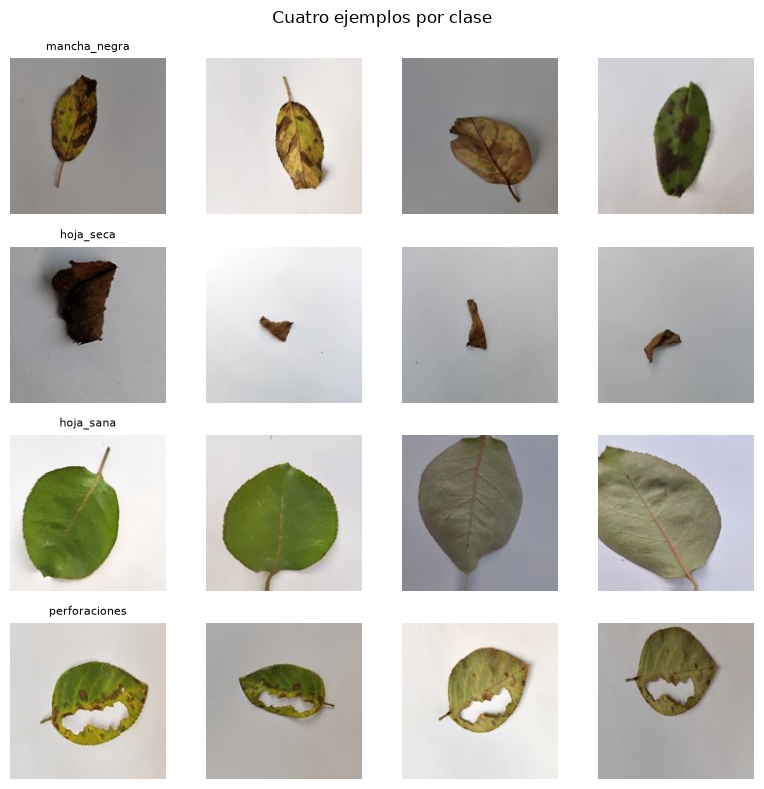

In [3]:
import csv
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

filas = list(csv.DictReader(open(ROOT / "data" / "processed" / "metadata.csv", encoding="utf-8")))
tabla = pd.DataFrame(filas)
conteo = tabla["clase"].value_counts().reindex(
    ["mancha_negra", "hoja_seca", "hoja_sana", "perforaciones"]
)
print("Imágenes:", len(tabla))
print(conteo.to_string())

fig, ejes = plt.subplots(4, 4, figsize=(8, 8))
for fila_i, clase in enumerate(conteo.index):
    grupo = tabla[tabla["clase"] == clase].head(4)
    for col_i, (_, registro) in enumerate(grupo.iterrows()):
        ejes[fila_i, col_i].imshow(Image.open(ROOT / "data" / "processed" / registro["archivo"]))
        ejes[fila_i, col_i].set_title(clase if col_i == 0 else "", fontsize=8)
        ejes[fila_i, col_i].axis("off")
fig.suptitle("Cuatro ejemplos por clase")
fig.tight_layout()
plt.show()

## 5. Preprocesamiento y características

Todas las fotos se pasan a RGB. No se borró el fondo: en este dataset ya es claro y forma parte de la apariencia que verá la API.

- **Color.** Histograma HSV (16 bins de tono, 8 de saturación, 8 de valor), media y desviación RGB, y la proporción del canal verde. Son 39 números. Sirven para separar una hoja verde de una hoja marrón, pero no describen la forma de una mancha.
- **Textura.** HOG sobre la hoja en gris a 64×64 (8 orientaciones, celdas de 8 px). Aporta el dibujo de manchas, bordes y agujeros.
- El vector completo mide 1 607 números y es el que usa el modelo elegido.

No hay aumento de datos adicional aquí: la fuente augmented ya trae copias modificadas. Eso puede hacer que una hoja parecida quede en train y en test. La accuracy debe leerse como línea base de laboratorio, no como rendimiento en campo.

In [4]:
from backend.ml import extraer_caracteristicas, extraer_color

ejemplo = Image.open(ROOT / "data" / "processed" / "mancha_negra" / "mancha_negra_000.jpg")
print("Tamaño de la muestra:", ejemplo.size)
print("Vector de color:", extraer_color(ejemplo).shape)
print("Vector color + HOG:", extraer_caracteristicas(ejemplo).shape)

Tamaño de la muestra: (160, 160)
Vector de color: (39,)
Vector color + HOG: (1607,)


## 6. Partición, baseline y modelo elegido

`entrenar_modelo.py` hace una partición estratificada 70 % / 15 % / 15 % con semilla 42.

| Modelo | Qué usa | Para qué está |
| --- | --- | --- |
| `DummyClassifier` (mayoría) | Ninguna característica útil | Piso: con clases equilibradas no puede pasar de 0.25 |
| Regresión logística | Solo color, estandarizado | Baseline simple y rápido |
| Bosque aleatorio | Color + HOG, 200 árboles | Modelo que usa la API |

La celda siguiente vuelve a entrenar y sobrescribe `models/modelo.joblib` y `models/metricas.json`. Tarda un par de minutos.

In [5]:
import entrenar_modelo

entrenar_modelo.main()

Imágenes: 720 | train 503 | val 109 | test 108
Extrayendo características...
mayoria: accuracy=0.250 f1_macro=0.100
regresion_logistica_color: accuracy=0.824 f1_macro=0.822
bosque_color_textura: accuracy=0.880 f1_macro=0.874
Validación del bosque: accuracy=0.835
Modelo guardado en models\modelo.joblib


## 7. Métricas y matriz de confusión

Se informa accuracy y F1 macro en el conjunto de test, que no entra al `fit`. La validación sirve para ver si el test quedó muy por encima o muy por debajo. Si al reentrenar los números cambian, conserva la semilla y el mismo `metadata.csv`: con eso el resultado es el mismo.

Partición: 503 train / 109 val / 108 test
Validación del bosque: 0.8349


,modelo,accuracy,f1_macro
0,mayoria,0.2500,0.1000
1,regresion_logistica_color,0.8241,0.8219
2,bosque_color_textura,0.8796,0.8736


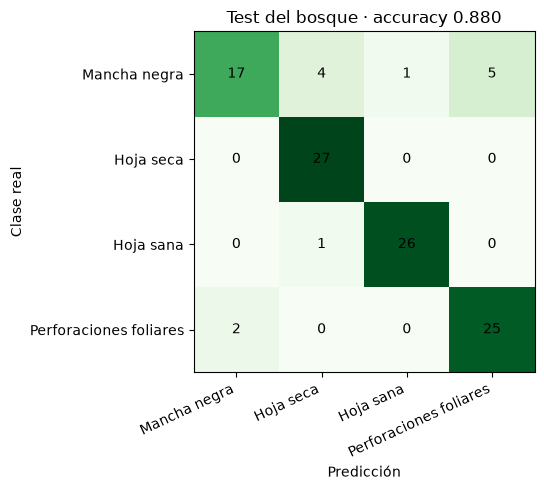

Las imágenes augmented pueden ser transformaciones de la misma hoja. La partición aleatoria puede ser optimista frente a un cultivo nuevo. No usar como diagnóstico de campo.


In [6]:
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

metricas = json.loads((ROOT / "models" / "metricas.json").read_text(encoding="utf-8"))
resumen = pd.DataFrame(
    [{"modelo": item["nombre"], "accuracy": item["accuracy"], "f1_macro": item["f1_macro"]} for item in metricas["modelos"]]
)
print("Partición:", metricas["n_train"], "train /", metricas["n_validacion"], "val /", metricas["n_test"], "test")
print("Validación del bosque:", metricas["validacion"]["accuracy"])
display(resumen)

elegido = next(item for item in metricas["modelos"] if item["nombre"] == "bosque_color_textura")
matriz = np.array(elegido["matriz_confusion"])
nombres = [metricas["etiquetas"][clave] for clave in metricas["clases"]]
fig, eje = plt.subplots(figsize=(6.2, 5))
eje.imshow(matriz, cmap="Greens")
eje.set_xticks(range(len(nombres)), nombres, rotation=25, ha="right")
eje.set_yticks(range(len(nombres)), nombres)
for i in range(len(nombres)):
    for j in range(len(nombres)):
        eje.text(j, i, int(matriz[i, j]), ha="center", va="center")
eje.set_xlabel("Predicción")
eje.set_ylabel("Clase real")
eje.set_title(f"Test del bosque · accuracy {elegido['accuracy']:.3f}")
fig.tight_layout()
plt.show()
print(metricas["nota"])

## 8. Análisis de errores

En la corrida de referencia el bosque supera a la logística de color (cerca de 0.88 frente a 0.82) y los dos quedan muy por encima del piso de 0.25. La hoja seca y la hoja sana se separan bien porque el color ya las distingue. La **mancha negra** es la clase débil: muchas de sus hojas también están amarillentas o tienen tejido perdido, así que el modelo las manda a hoja seca o a perforaciones.

Consecuencias para el producto:

- Una confianza baja (por ejemplo bajo 0.45) no debería mostrarse como un diagnóstico cerrado.
- Conviene pedir otra foto con la hoja completa y el fondo claro.
- Ampliar el dataset con hojas de otras fincas, sin mezclar copias augmented de la misma hoja en train y test, es el siguiente experimento serio.

## 9. Inferencia sobre imágenes del dataset

Esta celda no llama a la API: usa el mismo `predecir` que el backend. Así se puede comprobar el detector aunque MongoDB y Uvicorn estén apagados.

mancha_negra     -> Mancha negra             84%  | Retira y no compostes las hojas con manchas. Mejora la ventilación, evita mojar el follaje...
hoja_seca        -> Hoja seca                86%  | Revisa riego, drenaje, sales del sustrato y exposición al sol. Elimina tejido seco y compa...
hoja_sana        -> Hoja sana                81%  | Mantén un manejo preventivo: riego en la base, poda de aireación y vigilancia semanal de m...
perforaciones    -> Perforaciones foliares   81%  | Inspecciona el envés y los brotes en busca de larvas o escarabajos. Retira hojas muy dañad...


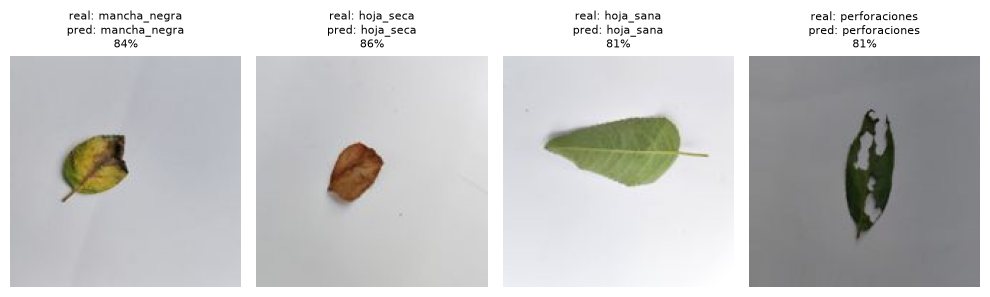

In [7]:
from backend.ml import predecir

muestras = {
    "mancha_negra": "mancha_negra_135.jpg",
    "hoja_seca": "hoja_seca_165.jpg",
    "hoja_sana": "hoja_sana_015.jpg",
    "perforaciones": "perforaciones_020.jpg",
}
fig, ejes = plt.subplots(1, 4, figsize=(10, 3.2))
for eje, clase in zip(ejes, muestras):
    ruta = ROOT / "data" / "processed" / clase / muestras[clase]
    imagen = Image.open(ruta)
    resultado = predecir(imagen)
    eje.imshow(imagen)
    eje.axis("off")
    eje.set_title(f"real: {clase}\npred: {resultado['clase']}\n{resultado['confianza']:.0%}", fontsize=8)
    print(f"{clase:16} -> {resultado['etiqueta']:24} {resultado['confianza']:.0%}  | {resultado['recomendacion'][:90]}...")
fig.tight_layout()
plt.show()

## 10. Probar la API y la persistencia

En **otro** cmd.exe, con el entorno activo y en la raíz del proyecto:

```bat
python -m uvicorn backend.api:app --reload --host 127.0.0.1 --port 8000
```

La interfaz, en una tercera ventana:

```bat
python -m streamlit run frontend/app.py
```

MongoDB es opcional. Con `PERSISTENCE=auto` en `.env`, si `mongod` no está encendido el diagnóstico se guarda en `data/diagnosticos.json`. Para forzar la base: instala MongoDB Community, arranca `mongod --dbpath C:\data\db` y deja `MONGO_URI=mongodb://127.0.0.1:27017`.

In [8]:
import os

import requests
from dotenv import load_dotenv

load_dotenv(ROOT / ".env")
API = os.getenv("API_URL", "http://127.0.0.1:8000").rstrip("/")
try:
    estado = requests.get(API + "/health", timeout=3)
    estado.raise_for_status()
    print("API:", estado.json())
    ruta = ROOT / "data" / "processed" / "perforaciones" / "perforaciones_030.jpg"
    with ruta.open("rb") as archivo:
        respuesta = requests.post(
            API + "/diagnosticos",
            files={"file": (ruta.name, archivo.read(), "image/jpeg")},
            timeout=60,
        )
    if respuesta.ok:
        cuerpo = respuesta.json()
        print(cuerpo["etiqueta"], cuerpo["confianza"], "guardado en", cuerpo["persistencia"], "id", cuerpo["id"])
        print(cuerpo["aviso"])
    else:
        print("La API rechazó la imagen:", respuesta.status_code, respuesta.text[:400])
except requests.RequestException as exc:
    print("API no disponible (" + type(exc).__name__ + "). El modelo local de la celda anterior sí está listo.")
    print("Arranca Uvicorn en otro cmd.exe y vuelve a ejecutar esta celda.")

API no disponible (ConnectionError). El modelo local de la celda anterior sí está listo.
Arranca Uvicorn en otro cmd.exe y vuelve a ejecutar esta celda.


## 11. Pruebas automáticas y cierre

En cmd.exe, desde la raíz:

```bat
python -m pytest -q
```

Esas pruebas cubren archivos que no son imagen, imágenes dañadas, el contrato de la predicción y el historial en JSON. No llaman a un servicio de pago ni exigen MongoDB.

**Cierre.** El laboratorio cumple el ciclo pedido: problema acotado a enfermedades y daños foliares del rosal, dataset público citado, preprocesamiento explícito, comparación contra un baseline más simple, modelo guardado, inferencia, API, persistencia e interfaz. El error principal está identificado (mancha negra frente a otras necrosis) y el aviso al usuario deja claro que el sistema no certifica la sanidad de la planta.